In [ ]:
import pandas as pd
import re

latex_rows = r"""
\begin{tabular}{@{}l r r r r r@{}}
\toprule
\textbf{Model} & \textbf{SC} $\uparrow$ & \textbf{LC} $\uparrow$ & \textbf{CC} $\uparrow$ & \textbf{CSR} $\downarrow$ & \textbf{JS} $\uparrow$ \\
\midrule
\rowcolor{hlgreen}
DeepSeek-V3.2         & .964 & \best{.958} & .976 & \best{.029} & \best{.923} \\
\rowcolor{hlgreen}
DeepSeek-V3.1         & .964 & \best{.934} & .964 & .057 & \best{.893} \\
\rowcolor{hlgreen}
Qwen3-Max             & .964 & .917 & .970 & .061 & \best{.887} \\
Claude Sonnet 4.6     & .934 & \best{.964} & .976 & \best{.018} & .875 \\
DeepSeek-R1$^\dagger$ & .911 & .905 & .946 & \best{.016} & .863 \\
Gemini 2.5 Pro        & \best{.970} & .887 & \best{.994} & .046 & .857 \\
Gemini 2.5 Flash      & .934 & .917 & \best{1.000} & .033 & .851 \\
MiniMax-M2.7          & .958 & .881 & .982 & .041 & .833 \\
Qwen3.5-Flash         & .958 & .863 & .970 & .115 & .827 \\
GPT-4.1               & .905 & .899 & .982 & .075 & .821 \\
Qwen3.5-Plus          & .934 & .875 & .982 & .084 & .821 \\
GPT-5.4               & .934 & .875 & .982 & .040 & .804 \\
GPT-5.4-mini          & .941 & .851 & .976 & .067 & .798 \\
MiniMax-M2.5          & .958 & .833 & .976 & .084 & .798 \\
Claude Haiku 4.5      & .899 & .911 & .923 & .045 & .750 \\
Claude Opus 4.6       & .929 & .851 & \worst{.923} & .078 & .750 \\
\rowcolor{hlred}
LLaMA-3.1-8B          & \worst{.827} & .893 & .964 & .097 & .750 \\
\rowcolor{hlred}
LLaMA-3.3-70B         & .875 & \worst{.804} & .982 & \worst{.168} & \worst{.720} \\
\rowcolor{hlred}
GPT-5.3-Codex         & .923 & \worst{.827} & \worst{.934} & .076 & \worst{.708} \\
\rowcolor{hlred}
LLaMA-3               & \worst{.833} & \worst{.780} & \worst{.869} & \worst{.153} & \worst{.637} \\
\midrule
\textit{Mean}         & .926 & .881 & .964 & .076 & .808 \\
\bottomrule
\end{tabular}
"""

columns = ['Model', 'SC', 'LC', 'CC', 'CSR', 'JS']

# 跳过这些行
skip_patterns = [
    r'\\begin', r'\\end', r'\\toprule', r'\\midrule', 
    r'\\bottomrule', r'\\rowcolor', r'\\textbf', r'^\s*$'
]

rows = []
for line in latex_rows.strip().split('\n'):
    line = line.strip()
    
    # 跳过非数据行
    if '&' not in line:
        continue
    
    # 跳过 header 行（含 textbf）
    if r'\textbf' in line:
        continue
    
    # 去掉行尾 \\
    line = re.sub(r'\\\\.*$', '', line).strip()
    
    # 去掉 \best{} \worst{} \textit{} 等，保留内容
    line = re.sub(r'\\[a-zA-Z]+\{([^}]*)\}', r'\1', line)
    
    # 去掉 $^\dagger$ 等数学符号
    line = re.sub(r'\$[^$]*\$', '', line)
    
    # 去掉剩余 LaTeX 命令
    line = re.sub(r'\\[a-zA-Z]+', '', line).strip()
    
    cols = [c.strip() for c in line.split('&')]
    
    if len(cols) == len(columns):
        rows.append(cols)

df = pd.DataFrame(rows, columns=columns)

# 数字列转 float
for col in columns[1:]:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df

,Model,SC,LC,CC,CSR,JS
0,DeepSeek-V3.2,0.964,0.958,0.976,0.029,0.923
1,DeepSeek-V3.1,0.964,0.934,0.964,0.057,0.893
2,Qwen3-Max,0.964,0.917,0.970,0.061,0.887
3,Claude Sonnet 4.6,0.934,0.964,0.976,0.018,0.875
4,DeepSeek-R1,0.911,0.905,0.946,0.016,0.863
5,Gemini 2.5 Pro,0.970,0.887,0.994,0.046,0.857
6,Gemini 2.5 Flash,0.934,0.917,1.000,0.033,0.851
7,MiniMax-M2.7,0.958,0.881,0.982,0.041,0.833
8,Qwen3.5-Flash,0.958,0.863,0.970,0.115,0.827
9,GPT-4.1,0.905,0.899,0.982,0.075,0.821


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ============ 1. 加分类列 ============
tier_map = {
    'Frontier': ['DeepSeek-V3.2', 'DeepSeek-V3.1', 'Qwen3-Max', 'Claude Sonnet 4.6', 
                 'DeepSeek-R1', 'Gemini 2.5 Pro', 'GPT-4.1', 'GPT-5.4', 'Claude Opus 4.6'],
    'Mid-tier': ['Gemini 2.5 Flash', 'MiniMax-M2.7', 'Qwen3.5-Plus', 'GPT-5.4-mini', 
                 'MiniMax-M2.5', 'Claude Haiku 4.5', 'LLaMA-3.3-70B', 'GPT-5.3-Codex'],
    'Lightweight': ['Qwen3.5-Flash', 'LLaMA-3.1-8B', 'LLaMA-3']
}

# 反转成 model -> tier 的字典
model_to_tier = {}
for tier, models in tier_map.items():
    for model in models:
        model_to_tier[model] = tier

df['Tier'] = df['Model'].map(model_to_tier)

# 去掉 Mean 行
df_plot = df[df['Model'] != 'Mean'].copy()

print(df_plot[['Model', 'Tier']])

# ============ 2. 画 Error Bar Plot ============
metrics = ['SC', 'LC', 'CC', 'CSR', 'JS']
tiers = ['Frontier', 'Mid-tier', 'Lightweight']
colors = {'Frontier': '#2196F3', 'Mid-tier': '#FF9800', 'Lightweight': '#F44336'}

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(metrics))
width = 0.25

for i, tier in enumerate(tiers):
    tier_df = df_plot[df_plot['Tier'] == tier]
    means = tier_df[metrics].mean()
    stds = tier_df[metrics].std()
    
    ax.bar(x + i * width, means, width,
           label=tier,
           color=colors[tier],
           alpha=0.8,
           yerr=stds,
           capsize=5,
           error_kw={'linewidth': 1.5})

ax.set_xticks(x + width)
ax.set_xticklabels(metrics, fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Performance by Tier (Mean ± Std)', fontsize=14)
ax.legend(title='Model Tier', fontsize=10)
ax.set_ylim(0, 1.1)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

: 

In [2]:
fig, axes = plt.subplots(1, len(metrics), figsize=(15, 5))

for ax, metric in zip(axes, metrics):
    for i, tier in enumerate(tiers):
        tier_df = df_plot[df_plot['Tier'] == tier]
        vals = tier_df[metric]
        
        # error bar
        ax.errorbar(i, vals.mean(), yerr=vals.std(),
                    fmt='o', color=colors[tier],
                    capsize=5, markersize=8, linewidth=2)
        
        # 每个数据点
        ax.scatter([i]*len(vals), vals,
                   color=colors[tier], alpha=0.4, s=30)
    
    ax.set_title(metric, fontsize=12)
    ax.set_xticks([0,1,2])
    ax.set_xticklabels(['Frontier','Mid','Light'], fontsize=9)
    ax.set_ylim(0, 1.1)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Performance by Model Tier', fontsize=14)
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

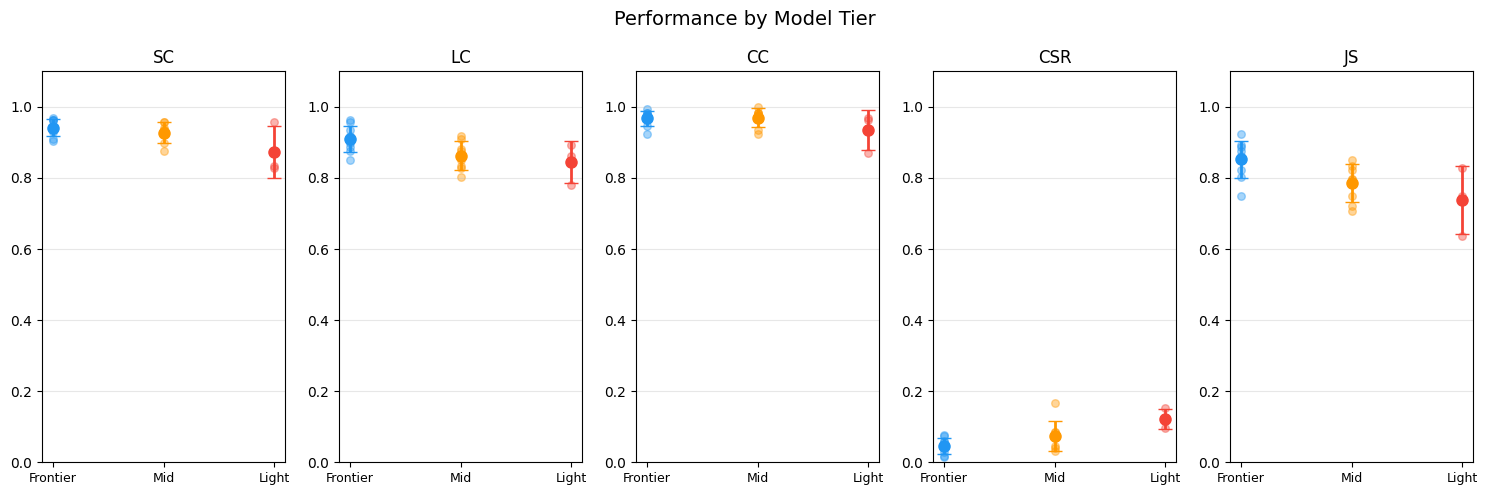

In [12]:
fig, axes = plt.subplots(1, len(metrics), figsize=(15, 5))

for ax, metric in zip(axes, metrics):
    for i, tier in enumerate(tiers):
        tier_df = df_plot[df_plot['Tier'] == tier]
        vals = tier_df[metric]
        
        # error bar
        ax.errorbar(i, vals.mean(), yerr=vals.std(),
                    fmt='o', color=colors[tier],
                    capsize=5, markersize=8, linewidth=2)
        
        # 每个数据点
        ax.scatter([i]*len(vals), vals,
                   color=colors[tier], alpha=0.4, s=30)
    
    ax.set_title(metric, fontsize=12)
    ax.set_xticks([0,1,2])
    ax.set_xticklabels(['Frontier','Mid','Light'], fontsize=9)
    ax.set_ylim(0, 1.1)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Performance by Model Tier', fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 加发布时间（大概）
release_dates = {
    'LLaMA-3':           '2024-04',
    'LLaMA-3.1-8B':      '2024-07',
    'LLaMA-3.3-70B':     '2024-12',
    'GPT-4.1':           '2025-04',
    'GPT-5.3-Codex':     '2025-05',
    'GPT-5.4':           '2025-06',
    'GPT-5.4-mini':      '2025-06',
    'Gemini 2.5 Flash':  '2025-03',
    'Gemini 2.5 Pro':    '2025-03',
    'Claude Haiku 4.5':  '2025-05',
    'Claude Sonnet 4.6': '2025-06',
    'Claude Opus 4.6':   '2025-06',
    'DeepSeek-R1':       '2025-01',
    'DeepSeek-V3.1':     '2025-03',
    'DeepSeek-V3.2':     '2025-04',
    'Qwen3-Max':         '2025-04',
    'Qwen3.5-Flash':     '2025-05',
    'Qwen3.5-Plus':      '2025-05',
    'MiniMax-M2.5':      '2025-03',
    'MiniMax-M2.7':      '2025-05',
}

colors = {'Frontier': '#2196F3', 'Mid-tier': '#FF9800', 'Lightweight': '#F44336'}

df_plot = df[df['Model'] != 'Mean'].copy()
df_plot['Release'] = df_plot['Model'].map(release_dates)
df_plot['Release'] = pd.to_datetime(df_plot['Release'])
df_plot = df_plot.dropna(subset=['Release']).sort_values('Release')

fig, ax = plt.subplots(figsize=(12, 6))

for _, row in df_plot.iterrows():
    tier = row['Tier']
    color = colors.get(tier, 'gray')
    ax.scatter(row['Release'], row['JS'], 
               color=color, s=80, zorder=5)
    ax.annotate(row['Model'], 
                (row['Release'], row['JS']),
                textcoords='offset points',
                xytext=(5, 3), fontsize=7, alpha=0.8)

# 加趋势线
x_num = df_plot['Release'].astype(np.int64)
z = np.polyfit(x_num, df_plot['JS'], 1)
p = np.poly1d(z)
ax.plot(df_plot['Release'], p(x_num), 
        '--', color='gray', alpha=0.5, label='Trend')

# 图例
for tier, color in colors.items():
    ax.scatter([], [], color=color, label=tier, s=80)

ax.set_xlabel('Release Date', fontsize=12)
ax.set_ylabel('JSimport matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import stats

# 假设 df_plot 已经有 Release 列（datetime）和 Tier 列
# 如果没有，先运行之前的代码

colors = {'Frontier': '#2196F3', 'Mid-tier': '#FF9800', 'Lightweight': '#F44336'}
tiers = ['Frontier', 'Mid-tier', 'Lightweight']

fig, ax = plt.subplots(figsize=(12, 6))

# ============ 画散点 + 标注 ============
for _, row in df_plot.iterrows():
    tier = row['Tier']
    color = colors.get(tier, 'gray')
    ax.scatter(row['Release'], row['JS'],
               color=color, s=80, zorder=5)
    ax.annotate(row['Model'],
                (row['Release'], row['JS']),
                textcoords='offset points',
                xytext=(5, 3), fontsize=7, alpha=0.8)

# ============ 趋势线 + Pearson r ============
x_num = df_plot['Release'].astype(np.int64)
y = df_plot['JS']

# 计算 Pearson r 和 p 值
r, p_value = stats.pearsonr(x_num, y)

# 趋势线
z = np.polyfit(x_num, y, 1)
p = np.poly1d(z)

# p 值显示格式
if p_value < 0.001:
    p_str = 'p < 0.001'
elif p_value < 0.01:
    p_str = 'p < 0.01'
elif p_value < 0.05:
    p_str = 'p < 0.05'
else:
    p_str = f'p = {p_value:.3f}'

ax.plot(df_plot['Release'].sort_values(),
        p(x_num.sort_values()),
        '--', color='gray', alpha=0.5,
        label=f'Trend (r = {r:.3f}, {p_str})')

# ============ 图例 ============
for tier, color in colors.items():
    ax.scatter([], [], color=color, label=tier, s=80)

ax.set_xlabel('Release Date', fontsize=12)
ax.set_ylabel('JS Score ↑', fontsize=12)
ax.set_title('Model Performance over Time', fontsize=14)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# ============ 在图上显示 r 值 ============
ax.text(0.05, 0.95,
        f'Pearson r = {r:.3f}\n{p_str}',
        transform=ax.transAxes,
        fontsize=11,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

print(f'Pearson r = {r:.3f}, {p_str}') Score ↑', fontsize=12)
ax.set_title('Model Performance over Time', fontsize=14)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

SyntaxError: unterminated string literal (detected at line 60) (3202455387.py, line 60)

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 加发布时间（大概）
release_dates = {
    'LLaMA-3':           '2024-04',
    'LLaMA-3.1-8B':      '2024-07',
    'LLaMA-3.3-70B':     '2024-12',
    'GPT-4.1':           '2025-04',
    'GPT-5.3-Codex':     '2025-05',
    'GPT-5.4':           '2025-06',
    'GPT-5.4-mini':      '2025-06',
    'Gemini 2.5 Flash':  '2025-03',
    'Gemini 2.5 Pro':    '2025-03',
    'Claude Haiku 4.5':  '2025-05',
    'Claude Sonnet 4.6': '2025-06',
    'Claude Opus 4.6':   '2025-06',
    'DeepSeek-R1':       '2025-01',
    'DeepSeek-V3.1':     '2025-03',
    'DeepSeek-V3.2':     '2025-04',
    'Qwen3-Max':         '2025-04',
    'Qwen3.5-Flash':     '2025-05',
    'Qwen3.5-Plus':      '2025-05',
    'MiniMax-M2.5':      '2025-03',
    'MiniMax-M2.7':      '2025-05',
}

colors = {'Frontier': '#2196F3', 'Mid-tier': '#FF9800', 'Lightweight': '#F44336'}

df_plot = df[df['Model'] != 'Mean'].copy()
df_plot['Release'] = df_plot['Model'].map(release_dates)
df_plot['Release'] = pd.to_datetime(df_plot['Release'])
df_plot = df_plot.dropna(subset=['Release']).sort_values('Release')

fig, ax = plt.subplots(figsize=(12, 6))

for _, row in df_plot.iterrows():
    tier = row['Tier']
    color = colors.get(tier, 'gray')
    ax.scatter(row['Release'], row['JS'], 
               color=color, s=80, zorder=5)
    ax.annotate(row['Model'], 
                (row['Release'], row['JS']),
                textcoords='offset points',
                xytext=(5, 3), fontsize=7, alpha=0.8)

# 加趋势线
x_num = df_plot['Release'].astype(np.int64)
z = np.polyfit(x_num, df_plot['JS'], 1)
p = np.poly1d(z)
ax.plot(df_plot['Release'], p(x_num), 
        '--', color='gray', alpha=0.5, label='Trend')

# 图例
for tier, color in colors.items():
    ax.scatter([], [], color=color, label=tier, s=80)

ax.set_xlabel('Release Date', fontsize=12)
ax.set_ylabel('JS Score ↑', fontsize=12)
ax.set_title('Model Performance over Time', fontsize=14)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import stats

# 假设 df_plot 已经有 Release 列（datetime）和 Tier 列
# 如果没有，先运行之前的代码

colors = {'Frontier': '#2196F3', 'Mid-tier': '#FF9800', 'Lightweight': '#F44336'}
tiers = ['Frontier', 'Mid-tier', 'Lightweight']

fig, ax = plt.subplots(figsize=(12, 6))

# ============ 画散点 + 标注 ============
for _, row in df_plot.iterrows():
    tier = row['Tier']
    color = colors.get(tier, 'gray')
    ax.scatter(row['Release'], row['JS'],
               color=color, s=80, zorder=5)
    ax.annotate(row['Model'],
                (row['Release'], row['JS']),
                textcoords='offset points',
                xytext=(5, 3), fontsize=7, alpha=0.8)

# ============ 趋势线 + Pearson r ============
x_num = df_plot['Release'].astype(np.int64)
y = df_plot['JS']

# 计算 Pearson r 和 p 值
r, p_value = stats.pearsonr(x_num, y)

# 趋势线
z = np.polyfit(x_num, y, 1)
p = np.poly1d(z)

# p 值显示格式
if p_value < 0.001:
    p_str = 'p < 0.001'
elif p_value < 0.01:
    p_str = 'p < 0.01'
elif p_value < 0.05:
    p_str = 'p < 0.05'
else:
    p_str = f'p = {p_value:.3f}'

ax.plot(df_plot['Release'].sort_values(),
        p(x_num.sort_values()),
        '--', color='gray', alpha=0.5,
        label=f'Trend (r = {r:.3f}, {p_str})')

# ============ 图例 ============
for tier, color in colors.items():
    ax.scatter([], [], color=color, label=tier, s=80)

ax.set_xlabel('Release Date', fontsize=12)
ax.set_ylabel('JS Score ↑', fontsize=12)
ax.set_title('Model Performance over Time', fontsize=14)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# ============ 在图上显示 r 值 ============
ax.text(0.05, 0.95,
        f'Pearson r = {r:.3f}\n{p_str}',
        transform=ax.transAxes,
        fontsize=11,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

print(f'Pearson r = {r:.3f}, {p_str}')

NameError: name 'df_plot' is not defined

: 